# Ethereum Gas Fee Study

**Question:** When is the cheapest time to send a transaction on Ethereum, how much could a company save by timing it, and what causes fee spikes?

**Data:** hourly summary of Ethereum blocks, Jan to Sep 2026, pulled from BigQuery with [`sql/hourly_gas.sql`](../sql/hourly_gas.sql) and saved as `data/gas_hourly.csv`.

## Step 2: Check the data

Load the hourly data and convert timestamps from UTC to New York time, so findings read as "weekday afternoons" rather than UTC hours.

In [1]:
import pandas as pd

df = pd.read_csv("../data/gas_hourly.csv")
df["hour"] = pd.to_datetime(df["hour"], utc=True).dt.tz_convert("America/New_York")
df.head()

,hour,blocks,avg_base_fee_gwei,tx_count,block_fullness
0,2025-12-31 19:00:00-05:00,299,0.035638,76759,0.506983
1,2025-12-31 20:00:00-05:00,300,0.030256,68399,0.511707
2,2025-12-31 21:00:00-05:00,299,0.031566,66667,0.512734
3,2025-12-31 22:00:00-05:00,297,0.031615,72503,0.505298
4,2025-12-31 23:00:00-05:00,299,0.029470,69984,0.510130


Run the checks. Two facts about Ethereum tell us what to expect: about one block every 12 seconds (about 300 per hour), and 9 months is about 6,550 hours.

In [2]:
print(len(df))                    # about 6,550?
print(df["blocks"].describe())    # mostly near 300?
print(df.isna().sum())            # anything missing?
print(df["avg_base_fee_gwei"].describe())

6552
count    6552.000000
mean      298.791972
std         1.182962
min       288.000000
25%       298.000000
50%       299.000000
75%       300.000000
max       300.000000
Name: blocks, dtype: float64
hour                 0
blocks               0
avg_base_fee_gwei    0
tx_count             0
block_fullness       0
dtype: int64
count    6552.000000
mean        0.267236
std         0.715701
min         0.026319
25%         0.058979
50%         0.111527
75%         0.195360
max        16.785048
Name: avg_base_fee_gwei, dtype: float64


### Data checks

- **Row count:** 6,552 hours, which is exactly 273 days × 24 hours from Jan 1 to Sep 30, 2026. No hours are missing.
- **Blocks per hour:** median 299, range 288 to 300. No suspicious hours, which fits one block every 12 seconds.
- **Missing values:** none in any column.
- **Fee range:** min 0.026 gwei, median 0.11 gwei, max 16.8 gwei. The max is about 150 times the median. These are real spikes to explain later, not errors to delete. The biggest ones cluster around Feb 5 and 6 and Sep 24.
- **Time zone:** converted from UTC to New York time so patterns read in business terms (for example "weekday afternoons") for a US company.

## Step 3: Explore

**My guess (written before looking at the data):**

I expect gas fees to be **highest in the morning and evening** (New York time) and **lowest overnight**.

**Why:** the morning and evening in New York overlap with trading hours in other parts of the world. Europe is active during the New York morning, and Asia opens during the New York evening. More traders online means more Ethereum transactions, which fills blocks and pushes the base fee up. Overnight in New York, fewer major markets are active, so demand and fees should drop.

Plot the hourly base fee across all 9 months to see the overall shape.

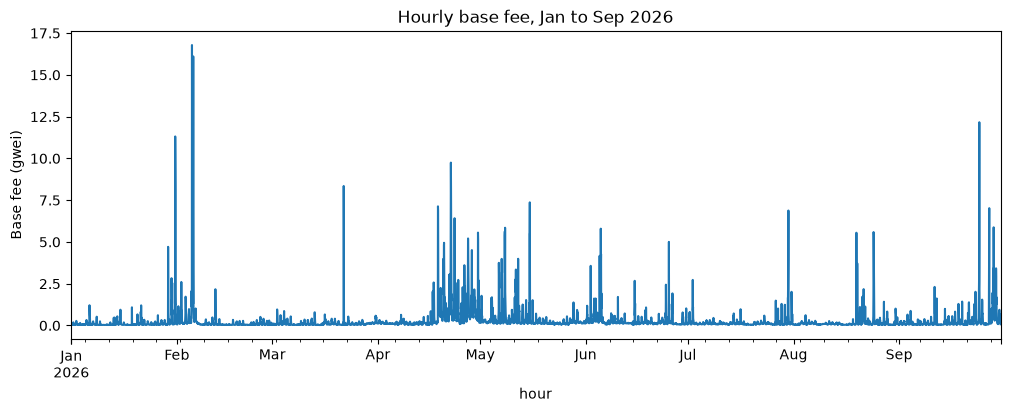

In [3]:
import matplotlib.pyplot as plt

df.set_index("hour")["avg_base_fee_gwei"].plot(figsize=(12, 4), title="Hourly base fee, Jan to Sep 2026")
plt.ylabel("Base fee (gwei)")
plt.show()

Compare the mean and median. If spikes pull the mean well above the median, the median is the better measure of a typical hour.

In [4]:
print("Mean:  ", round(df["avg_base_fee_gwei"].mean(), 3), "gwei")
print("Median:", round(df["avg_base_fee_gwei"].median(), 3), "gwei")

Mean:   0.267 gwei
Median: 0.112 gwei


### What I see

Fees sit near 0.1 gwei most of the time, with rare, sharp spikes up to about 17 gwei (early February, a busy stretch from mid April to mid May, and late September). Those spikes pull the mean (0.27 gwei) to more than double the median (0.11 gwei), so I'll use the **median** to describe a typical hour, because it isn't distorted by a handful of extreme hours.

## Step 4: Find the cheapest and most expensive times

A company needs a rule it can follow ("send on Sunday nights"), so arrange the data the way that decision is made: by **day of week** and **hour of day**. Each cell of the 7 × 24 grid is the **median** base fee for that slot.

In [5]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["hour_of_day"] = df["hour"].dt.hour
df["weekday"] = pd.Categorical(df["hour"].dt.day_name(), categories=order, ordered=True)

grid = df.pivot_table(index="weekday", columns="hour_of_day",
                      values="avg_base_fee_gwei", aggfunc="median", observed=False)

print("Cheapest slot:", grid.stack().idxmin(), round(grid.stack().min(), 3), "gwei")
print("Most expensive slot:", grid.stack().idxmax(), round(grid.stack().max(), 3), "gwei")
print("Ratio:", round(grid.stack().max() / grid.stack().min(), 1), "x")

Cheapest slot:

 ('Sunday', np.int32(22)) 0.058 gwei
Most expensive slot: ('Wednesday', np.int32(10)) 0.435 gwei
Ratio: 7.5 x


Draw the grid as a heatmap and save it for the README.

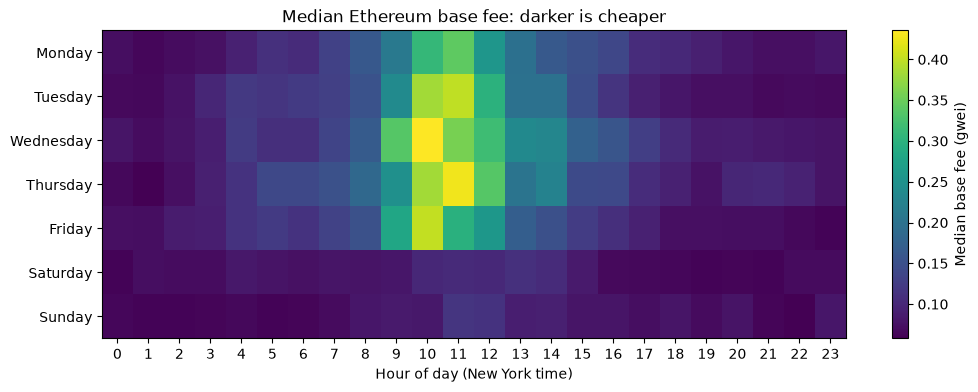

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(grid, aspect="auto", cmap="viridis")
ax.set_yticks(range(7))
ax.set_yticklabels(order)
ax.set_xticks(range(24))
ax.set_xlabel("Hour of day (New York time)")
ax.set_title("Median Ethereum base fee: darker is cheaper")
fig.colorbar(im, label="Median base fee (gwei)")
plt.savefig("../images/heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

Summarise the pattern by hour of day and by weekday.

In [7]:
print(grid.median(axis=0).round(3))   # typical fee by hour of day
print(grid.median(axis=1).round(3))   # typical fee by weekday

hour_of_day
0     0.068
1     0.066
2     0.073
3     0.089
4     0.113
5     0.111
6     0.109
7     0.131
8     0.154
9     0.238
10    0.383
11    0.342
12    0.258
13    0.197
14    0.163
15    0.142
16    0.115
17    0.093
18    0.080
19    0.073
20    0.077
21    0.072
22    0.069
23    0.078
dtype: float64
weekday
Monday       0.105
Tuesday      0.116
Wednesday    0.116
Thursday     0.126
Friday       0.111
Saturday     0.074
Sunday       0.075
dtype: float64


### Results vs. my guess

- **Cheapest:** Sunday around 10pm New York time (about 0.058 gwei). Evenings and overnight are cheap every day, and Saturday and Sunday are about 35% cheaper than weekdays.
- **Most expensive:** Wednesday around 10am New York time (about 0.435 gwei), roughly **7.5× the cheapest slot**. The peak runs from about 9am to 1pm on weekdays.
- **My guess:** partly right. I was right that **nights are cheap** and **mornings are expensive**, but wrong about **evenings**: New York evenings are among the cheapest hours. The peak lines up with the window when **US markets are open and Europe is still in its afternoon**, so the US and Europe overlap matters more than Asia's open. I also missed how much cheaper **weekends** are.

## Step 5: Explain what drives fees and spikes

**The rule to test:** when blocks are more than half full, the base fee rises for the next block; when they're less than half full, it falls. First, the simple version: do fuller hours have higher fees?

Correlation, fullness vs fee level: 0.017
Correlation, transactions vs fee level: -0.036


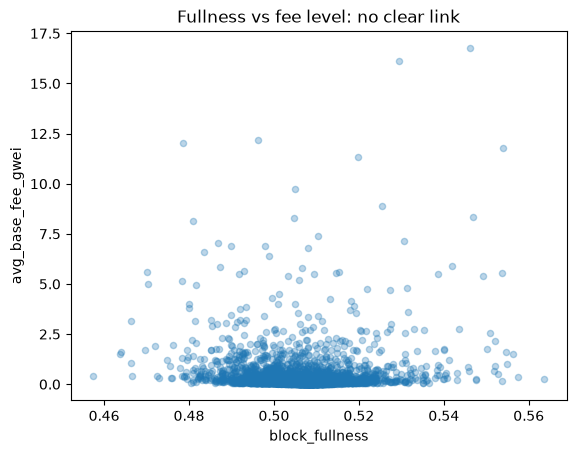

In [8]:
print("Correlation, fullness vs fee level:", round(df["avg_base_fee_gwei"].corr(df["block_fullness"]), 3))
print("Correlation, transactions vs fee level:", round(df["avg_base_fee_gwei"].corr(df["tx_count"]), 3))

df.plot.scatter(x="block_fullness", y="avg_base_fee_gwei", alpha=0.3,
                title="Fullness vs fee level: no clear link")
plt.show()

Almost no correlation. That doesn't break the rule; it shows the rule is working. The base fee keeps adjusting until blocks are back near **50% full** (fullness only ranges from about 0.46 to 0.56 here). So fullness doesn't set the fee's **level**; it sets the fee's **direction**. A better test: when an hour's blocks are more than half full, did the fee **rise** compared with the hour before?

In [9]:
import numpy as np

# change in fee vs the previous hour, on a log scale so +100% and -50% are treated symmetrically
df["fee_change"] = np.log(df["avg_base_fee_gwei"] / df["avg_base_fee_gwei"].shift(1))

print("Correlation, fullness vs fee change:", round(df["block_fullness"].corr(df["fee_change"]), 3))

df["over_half_full"] = df["block_fullness"] > 0.5
summary = df.groupby("over_half_full")["fee_change"].mean()
print("Avg fee change when blocks <= 50% full:", f"{np.exp(summary[False]) - 1:+.0%}")
print("Avg fee change when blocks >  50% full:", f"{np.exp(summary[True]) - 1:+.0%}")

Correlation, fullness vs fee change: 0.528
Avg fee change when blocks <= 50% full: -25%
Avg fee change when blocks >  50% full: +5%


Plot it and save the chart for the README.

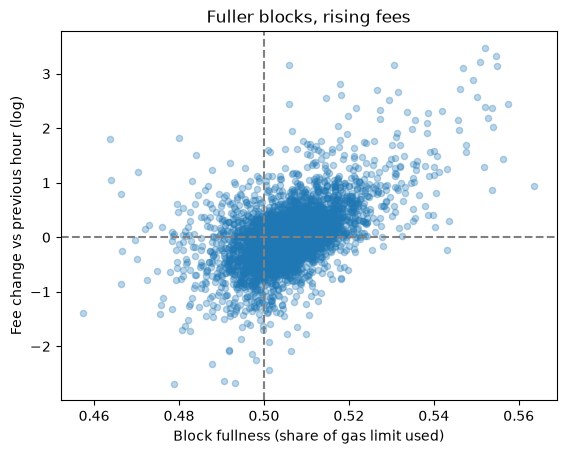

In [10]:
ax = df.plot.scatter(x="block_fullness", y="fee_change", alpha=0.3,
                     title="Fuller blocks, rising fees")
ax.axvline(0.5, color="gray", linestyle="--")
ax.axhline(0, color="gray", linestyle="--")
ax.set_xlabel("Block fullness (share of gas limit used)")
ax.set_ylabel("Fee change vs previous hour (log)")
plt.savefig("../images/fullness_vs_fee.png", dpi=150, bbox_inches="tight")
plt.show()

Now the 10 most expensive hours. These are the spikes to explain, not errors to delete.

In [11]:
df.nlargest(10, "avg_base_fee_gwei")[["hour", "avg_base_fee_gwei", "tx_count", "block_fullness"]]

,hour,avg_base_fee_gwei,tx_count,block_fullness
855,2026-02-05 10:00:00-05:00,16.785048,80599,0.546074
864,2026-02-05 19:00:00-05:00,16.105250,71445,0.529428
6401,2026-09-24 13:00:00-04:00,12.165422,74104,0.496218
861,2026-02-05 16:00:00-05:00,12.021276,88597,0.478671
860,2026-02-05 15:00:00-05:00,11.783881,79842,0.553977
737,2026-01-31 12:00:00-05:00,11.313869,76515,0.519709
2678,2026-04-22 10:00:00-04:00,9.748238,88628,0.504849
738,2026-01-31 13:00:00-05:00,8.896999,76471,0.525513
1923,2026-03-21 23:00:00-04:00,8.348972,34158,0.546974
2679,2026-04-22 11:00:00-04:00,8.284194,88892,0.504826


### What I found

**The rule shows up in the data.** Fullness has almost no link to the fee **level** (correlation 0.02), because the base fee adjusts until blocks are back near half full. But fullness strongly predicts the fee's **direction** (correlation 0.53): hours with blocks over 50% full saw the fee rise about 5% on average, while hours under 50% saw it fall about 25%. Transaction count barely matters (correlation −0.04); what counts is how much **gas** the blocks use, not how many transactions they hold.

**The top 10 spikes** fall on only 5 days (times are New York time):

| Date | Peak fee (gwei) | Hours in top 10 | Likely cause |
| --- | --- | --- | --- |
| Feb 5, 2026 | 16.8 | 4 | Crypto market crash: bitcoin fell toward $60,000 and over $1 billion in leveraged positions were liquidated. Panic selling and liquidations flooded the network. |
| Jan 31, 2026 | 11.3 | 2 | Weekend selloff: ETH fell about 9% after a record silver crash and the Fed chair nomination. |
| Apr 22, 2026 | 9.7 | 2 | Unclear. Prices rose after a US–Iran ceasefire extension and ETH ETF inflows, but the move was small (about +1%). Possible, not confirmed. |
| Sep 24, 2026 | 12.2 | 1 | Unknown. ETH pulled back after failing to break $2,800, but I found no clear event. |
| Mar 21, 2026 | 8.3 | 1 | Unknown. No major news found. This hour had unusually **few** transactions (about 34,000 vs about 75,000 typical), so a small number of very large transactions likely filled the blocks. |

**Takeaway:** the biggest spikes line up with **sudden market crashes**, when traders rush to sell, move funds, and get liquidated all at once. Six of the top 10 hours come from the two selloffs in late January and early February.

**Sources for the spike explanations:**

- Jan 31: [CNBC, Bitcoin dips below $79,000 as market digests silver sell-off](https://www.cnbc.com/2026/01/31/bitcoin-dips-below-78000-after-silver-selloff.html)
- Feb 5: [Bitcoin Magazine, Bitcoin price plunges toward $60,000](https://bitcoinmagazine.com/news/bitcoin-price-plunges-toward-60000) · [Yahoo Finance, Crypto liquidations hit $1.4 billion in 24 hours](https://finance.yahoo.com/news/crypto-liquidations-hit-1-4-183507624.html) · [Coinburn, Bitcoin's selloff accelerated toward $60,000](https://coinburn.com/news/bitcoin-february-5-2026-selloff-toward-60000) · [crypto.news, Ethereum price crash](https://crypto.news/ethereum-price-crash-what-can-investors-expect-in-february-2026/)
- Mar 21: [Crypto Integrated, Crypto news March 21, 2026](https://www.cryptointegrat.com/p/crypto-news-march-21-2026) (no Ethereum-specific event found)
- Apr 22: [Yahoo Finance, Bitcoin and Ethereum prices rising following ceasefire extension](https://finance.yahoo.com/personal-finance/investing/article/bitcoin-and-ethereum-prices-today-wednesday-april-22-2026-prices-rising-following-ceasefire-extension-114636596.html) · [TradingView, BTC tops $77K on peace](https://www.tradingview.com/news/financemagnates:144df810d094b:0-why-is-crypto-going-up-today-btc-tops-77k-on-peace-followed-by-ethereum-xrp-and-dogecoin/)
- Sep 24: [Fortune, Price of Ethereum on September 24, 2026](https://fortune.com/article/price-of-ethereum-09-24-2026/) · [usethebitcoin, ETH holds $2.6K after $2.8K rejection](https://usethebitcoin.com/eth/ethereum-price-september-24-2026/)

## Step 6: Turn it into dollars

A finance manager thinks in dollars, not gwei. Pull daily ETH prices from Yahoo Finance and work out what one simple transfer (21,000 gas) costs in each hour:

**Fee in dollars = gas × gwei ÷ 1,000,000,000 × ETH price**

In [12]:
import yfinance as yf

eth = yf.download("ETH-USD", start="2026-01-01", end="2026-10-01", progress=False)["Close"].squeeze()
eth.index = eth.index.date
df["date"] = df["hour"].dt.date
df["eth_price"] = df["date"].map(eth)

# The first 5 hours fall on Dec 31, 2025 in New York time, before the price download starts
print("Hours without an ETH price:", df["eth_price"].isna().sum())
print(eth.describe().round(0))

Hours without an ETH price: 5
count     273.0
mean     2205.0
std       415.0
min      1565.0
25%      1907.0
50%      2109.0
75%      2418.0
max      3355.0
Name: ETH-USD, dtype: float64


Cost of one simple transfer in each hour, then the weekday × hour grid of median dollar costs.

In [13]:
# cost of one simple transfer (21,000 gas) in dollars
df["transfer_cost_usd"] = 21000 * df["avg_base_fee_gwei"] / 1e9 * df["eth_price"]

cost_grid = df.pivot_table(index="weekday", columns="hour_of_day",
                           values="transfer_cost_usd", aggfunc="median", observed=False)
cheap, pricey = cost_grid.stack().min(), cost_grid.stack().max()
print("Cheapest slot:", cost_grid.stack().idxmin(), f"${cheap:.4f}")
print("Most expensive slot:", cost_grid.stack().idxmax(), f"${pricey:.4f}")
print(f"Savings on 100 transfers a month: ${(pricey - cheap) * 100:.2f}")

Cheapest slot: ('Sunday', np.int32(22)) $0.0025
Most expensive slot: ('Friday', np.int32(10)) $0.0207
Savings on 100 transfers a month: $1.82


Simple transfers are the cheapest kind of transaction. A token swap uses roughly 150,000 gas, about 7 times as much. Scale the same numbers up to see what timing is worth for a busier company, and look at the worst single hour.

In [14]:
swap_gas = 150_000
scale = swap_gas / 21000
print(f"One swap, cheapest slot: ${cheap * scale:.3f}  most expensive slot: ${pricey * scale:.3f}")
print(f"Savings on 1,000 swaps a month: ${(pricey - cheap) * scale * 1000:.0f}")

worst = df.loc[df["transfer_cost_usd"].idxmax()]
print(f"Worst single hour: {worst['hour']} at ${worst['transfer_cost_usd']:.2f} per transfer")

One swap, cheapest slot: $0.018  most expensive slot: $0.148
Savings on 1,000 swaps a month: $130
Worst single hour: 2026-09-24 13:00:00-04:00 at $0.69 per transfer


## Findings

**Cheapest time to send:** Sunday around 10pm New York time. Evenings, nights, and weekends are cheap in general. A simple transfer then costs about **$0.0025** (a quarter of a cent).

**Most expensive time:** weekday mornings, 9am to 1pm New York time, when US markets open while Europe is still trading. The worst slot costs about **$0.021** per transfer (Friday 10am in dollars, Wednesday 10am in gwei; the difference comes from ETH's price on those days), about **8× the cheapest**.

**What timing saves:** very little for simple transfers. Moving 100 transfers a month from the worst slot to the best saves about **$1.82**. Fees in 2026 are low enough that timing barely matters for small, simple transactions. It matters more at scale: for 1,000 token swaps a month (about 150,000 gas each), the same timing saves about **$130 a month**.

**What causes spikes:** sudden market crashes. The two biggest selloffs (Jan 31 and Feb 5) produced 6 of the 10 most expensive hours, when panic selling and liquidations filled blocks and the base fee climbed automatically, block after block. The worst single hour (Sep 24, 1pm) cost about **$0.69** per transfer, more than 100× a typical hour, and no schedule can avoid a spike like that.

**Rule for the company:** batch non-urgent transactions for evenings or weekends, avoid weekday mornings in New York, and hold off when markets are crashing.